# Building a Mooré image-word dataset from published dictionaries

Mooré is a low-resource language: very little text is written in it. I found no image dataset with human-written Mooré names for objects. The image sets that carry Mooré text are machine-translated captions (LAION-COCO-NLLB) and a benchmark that matches sentences to topic images (MVL-SIB). The best source of photos with Mooré words that I know of is a set of illustrated dictionaries compiled by Urs Niggli and published as PDFs on Webonary, mooreburkina.com and kusaal-bf.com. In a dictionary entry the headword is the Mooré word and a gloss is its French or English translation. About a third of the entries have a photo.

This notebook parses three of these PDFs and builds the table that notebook 2 uses to evaluate vision-language models and to fine-tune one: one row per photo, with the Mooré word, the French and English glosses, a category and a train, validation or test split. It also picks the test photos that can be asked about as a multiple-choice question and labels each as local to West Africa, global or unsure.

In [1]:
%pip install -q pymupdf imagehash

In [2]:
import collections, difflib, hashlib, io, os, random, re, unicodedata, warnings
import datasets, huggingface_hub
from types import SimpleNamespace
import imagehash, matplotlib.pyplot as plt, numpy as np, pandas as pd, pymupdf, torch
from datasets import Dataset, DatasetDict, Image as ImageFeature, Sequence, Value
from huggingface_hub import hf_hub_download, snapshot_download
from kaggle_secrets import UserSecretsClient
from PIL import Image
from transformers import AutoModel, AutoProcessor
from transformers.utils import logging as transformers_logging

hf_token = UserSecretsClient().get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = hf_token
warnings.filterwarnings("ignore")
transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()
seed = 20261007

## 1. The three dictionaries
The PDFs are free to download but carry no open licence, so they sit in a private repository on the Hub and a copy is in the bucket for reference. The table credits Urs Niggli and SIL International, and I will remove anything the authors ask me to remove. All three are compiled by Urs Niggli.

The main source is the illustrated Mooré-French-English dictionary printed from Webonary in 2021, which I call the Webonary print. It is the largest, it has the correct Mooré letters and it prints the headword as a caption under nearly every photo. The Lexique (2017) adds entries and photos for words that the Webonary print does not have. The body-parts list (2020) adds no records: I only use it to note, in the `sources` column, which entries it also contains.

In [3]:
pdf_repo = "anyantudre/moore-dictionaries-private"
pdf_files = {
    "webonary": "Dictionnaire Moore - français - English avec images.pdf",
    "lexique": "Moore Lexique comprimé.pdf",
    "body_parts": "Parties du corps en mooré.pdf",
}
pdfs = {
    name: pymupdf.open(hf_hub_download(pdf_repo, file, repo_type="dataset", token=hf_token))
    for name, file in pdf_files.items()
}
print({name: f"{len(pdf)} pages" for name, pdf in pdfs.items()})

{'webonary': '1886 pages', 'lexique': '320 pages', 'body_parts': '43 pages'}


### 1.1 Webonary print
This print is colour coded: black bold is the headword, blue the French gloss, green the English gloss, magenta the part of speech, red the sense number and brown a cross-reference. Small text is the "Frn" and "Eng" markers, and small bold digits are homograph numbers.

In [4]:
def nfc(text):
    return unicodedata.normalize("NFC", text)


marker_size, subscript_size = 10, 12  # font sizes in points
italic_flag = 2  # PyMuPDF font flag
colour_tags = {
    "0000ff": "french",
    "339966": "english",
    "ff00ff": "pos",
    "ff0000": "sense",
    "993300": "reference",
}


def tag_span(span):
    colour = "%06x" % span["color"]
    if span["size"] < marker_size:
        return "marker"
    if span["size"] < subscript_size:
        return "subscript"
    if colour in colour_tags:
        return colour_tags[colour]
    if colour != "000000" or span["flags"] & italic_flag:
        return "note"
    return "headword"


def read_lines(page):
    lines = []
    for block in page.get_text("dict")["blocks"]:
        for line in block.get("lines", []):
            spans, top = line["spans"], line["bbox"][1]
            if not spans or (
                spans[0]["flags"] == 4 and 9 < spans[0]["size"] < 11 and (top < 14 or top > 770)
            ):
                continue  # browser header and footer
            lines.append({"box": line["bbox"], "tokens": [(tag_span(s), s["text"]) for s in spans]})
    return lines

Nearly every photo has its headword printed under it, on the right side of the page. A caption is a line made only of headword text, close under a photo. A few captions sit at the top of the next page.

In [5]:
caption_min_x = 250  # captions are in the right half of the page
caption_gap = (-5, 45)  # distance in points between the bottom of a photo and its caption


def headword_only(tokens):
    kept = [
        (tag, text)
        for tag, text in tokens
        if tag != "subscript" and text.strip() and not text.strip().isdigit()
    ]
    if kept and all(tag == "headword" for tag, _ in kept):
        return "".join(text for _, text in kept).strip()


def closest_photo_above(line, photos, taken):
    x0, y0, x1, _ = line["box"]
    best = None
    for i, photo in enumerate(photos):
        left, _, right, bottom = photo["box"]
        gap = y0 - bottom
        under = caption_gap[0] <= gap <= caption_gap[1] or (
            bottom > 700 and y0 > 700 and gap >= caption_gap[0]
        )
        centred = abs((x0 + x1) / 2 - (left + right) / 2) < 95
        if i not in taken and under and centred and (best is None or abs(gap) < best[1]):
            best = (i, abs(gap))
    return best


def split_captions(lines, photos, waiting):
    captions, other = {}, []
    for line in lines:
        text = headword_only(line["tokens"])
        best = (
            closest_photo_above(line, photos, captions) if text and line["box"][0] > caption_min_x else None
        )
        if best:
            captions[best[0]] = text
        else:
            other.append(line)
    remaining = []
    for line in other:
        text = headword_only(line["tokens"])
        if waiting and text and line["box"][0] > caption_min_x and line["box"][1] < 120:
            waiting.pop(0)["caption"] = text
        else:
            remaining.append(line)
    for i, text in captions.items():
        photos[i]["caption"] = text
    return remaining, [photo for i, photo in enumerate(photos) if i not in captions and photo["box"][3] > 620]

In [6]:
def group_entries(lines):
    entries, current, carried, after_headword = [], None, [], False
    for line in lines:
        for n, (tag, text) in enumerate(line["tokens"]):
            if n == 0 and current and current["tokens"] and tag != "headword":
                previous = current["tokens"][-1][1]
                if previous and not previous.endswith(" ") and not text.startswith(" "):
                    text = " " + text  # wrapped line
            if tag == "subscript":
                continue
            if tag == "headword":
                new_line = (
                    n == 0 and line["box"][0] < 56
                )  # entries start at the left margin, wrapped lines are indented
                if current is None or not after_headword or new_line:
                    current = {"tokens": [], "box": list(line["box"])}
                    entries.append(current)
                current["tokens"].append((tag, text))
                after_headword = True
            else:
                (current["tokens"] if current else carried).append((tag, text))
                after_headword = False
    return carried, entries

Each entry is read token by token. For the gloss I keep the first French and English text of the first sense, and I stop reading glosses when an example sentence starts (its translation follows it).

In [7]:
guid = re.compile(r"[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4,12}", re.I)
category_code = re.compile(r"^\s*(\d+(?:\.\d+)*)\s*-\s*$")


def clean_words(words):
    return [w for w in words if w and re.search(r"[^\W\d_]", w) and not guid.search(w)]


def split_variants(text):
    return [nfc(v.strip(" .")) for v in re.split(r"[,;]", text) if v.strip(" .")]


def read_category(entry, tag, text):
    """Adds a token to the category block. Returns False when the block ends."""
    if tag == "english" and category_code.match(text):
        entry["categories"].append({"code": category_code.match(text).group(1), "french": "", "english": ""})
    elif tag in ("french", "english") and entry["categories"]:
        entry["categories"][-1][tag] = (entry["categories"][-1][tag] + text).strip()
    elif tag == "note" and ".)" in text:
        return False
    return True


def read_scientific_name(entry, tag, text):
    """Adds a token to the scientific name. Returns False when the name has ended."""
    if tag != "english":
        return False
    entry["scientific_name"] = re.sub(r"\s+", " ", entry["scientific_name"] + text).strip()
    return True


def read_reference(entry, state, text):
    value = nfc(text.strip())
    if state.label == "syn":
        entry["synonyms"].append(value)
    elif state.label == "unspec_of":
        entry["variant_of"] = value
    elif state.label != "ant":
        entry["variants"].append(value)


def read_gloss(entry, state, tag, text):
    if tag == "english" and "unspec." in text:
        state.label = "unspec_of" if " of" in text else "unspec_var"
    elif (
        not (tag == "english" and state.label in ("unspec_of", "unspec_var"))
        and state.language == tag
        and not state.example_seen
        and not state.first_sense_done
    ):
        entry[tag] += text
        entry["has_sense"] = True


def read_note(entry, state, text):
    if "(catégorie" in text or ("(cat" in text and ":" in text):
        state.region = None if ".)" in text.split(":", 1)[-1] else "category"
    elif "scient.:" in text:
        state.region = "scientific"
    elif "{e.g." in text or text.strip().startswith("{"):
        state.in_example, state.example_seen, entry["has_sense"] = "}" not in text, True, True
    elif re.search(r"var\.:\s*(.*)$", text):
        state.label = "var"
        entry["variants"] += split_variants(re.search(r"var\.:\s*(.*)$", text).group(1))
    elif state.label == "var" and text.strip(" .,;"):
        entry["variants"] += [v for v in split_variants(text) if not v.startswith("(")]
    elif not re.search(r"Empr\.:\s*(\w+)", text) and not entry["tone_raw"] and re.search(r"\[[^\]]*\]", text):
        entry["tone_raw"] = nfc(re.search(r"\[[^\]]*\]", text).group(0))


def parse_webonary_entry(tokens):
    n = 0
    while n < len(tokens) and tokens[n][0] == "headword":
        n += 1
    entry = {
        "moore": nfc("".join(t for _, t in tokens[:n]).strip()),
        "tone_raw": "",
        "pos": "",
        "french": "",
        "english": "",
        "scientific_name": "",
        "categories": [],
        "variants": [],
        "synonyms": [],
        "variant_of": "",
        "has_sense": False,
    }
    state = SimpleNamespace(
        language=None, label=None, region=None, in_example=False, example_seen=False, first_sense_done=False
    )
    for tag, text in tokens[n:]:
        if state.region == "category":
            if not read_category(entry, tag, text):
                state.region = None
            continue
        if state.region == "scientific":
            if read_scientific_name(entry, tag, text):
                continue
            state.region = None
        if state.in_example and tag in ("note", "headword"):
            state.in_example = "}" not in text
            continue
        if tag == "sense":
            state.first_sense_done = state.first_sense_done or entry["has_sense"]
        elif tag == "marker":
            state.language, state.label = (
                "french" if "Frn" in text else "english" if "Eng" in text else state.language
            ), None
        elif tag == "pos":
            word = text.strip()
            if word in ("syn:", "ant:"):
                state.label = word[:3]
            elif word and not entry["pos"]:
                entry["pos"] = word
        elif tag == "reference":
            read_reference(entry, state, text)
        elif tag in ("french", "english"):
            read_gloss(entry, state, tag, text)
        elif tag in ("note", "headword"):
            read_note(entry, state, text)
    entry["variants"], entry["synonyms"] = clean_words(entry["variants"]), clean_words(entry["synonyms"])
    for language in ("french", "english"):
        entry[language] = nfc(re.sub(r"\s+", " ", entry[language])).strip(" .,")
    return entry

In [8]:
def parse_webonary(pdf, pages):
    raw, photos, waiting = [], [], []
    for number in pages:
        page = pdf[number]
        photos_here = [
            {
                "xref": i["xref"],
                "box": tuple(i["bbox"]),
                "width": i["width"],
                "height": i["height"],
                "page": number + 1,
            }
            for i in page.get_image_info(xrefs=True)
            if i.get("xref")
        ]
        lines, waiting = split_captions(read_lines(page), photos_here, waiting)
        carried, entries = group_entries(lines)
        if carried and raw:
            raw[-1]["tokens"] += carried  # entry continues on the next page
        raw += [dict(e, page=number + 1) for e in entries]
        photos += photos_here
    entries = []
    for e in raw:
        entry = parse_webonary_entry(e["tokens"])
        if re.search(r"[^\W\d_]", entry["moore"]) and "\x10" not in entry["moore"]:
            entries.append(dict(entry, page=e["page"], box=[round(v, 1) for v in e["box"]]))
    return entries, photos


def match_key(word):
    return re.sub(r"\d+$", "", re.sub(r"\s+", "", nfc(word).lower()))


def link_photos_by_caption(entries, photos):
    """Photo index -> (entry index, where the caption was found, caption is unique)."""
    by_word = collections.defaultdict(list)
    for i, entry in enumerate(entries):
        by_word[match_key(entry["moore"])].append(i)
    links = {}
    for j, photo in enumerate(photos):
        candidates = by_word.get(match_key(photo.get("caption", "")), [])
        for where, page in (
            ("same_page", photo["page"]),
            ("prev_page", photo["page"] - 1),
            ("next_page", photo["page"] + 1),
        ):
            found = [i for i in candidates if entries[i]["page"] == page]
            if found:
                if where == "same_page":
                    found.sort(key=lambda i: abs(entries[i]["box"][1] - photo["box"][1]))
                links[j] = (found[-1] if where == "prev_page" else found[0], where, len(found) == 1)
                break
    return links

In [9]:
webonary_entries, webonary_photos = parse_webonary(pdfs["webonary"], range(len(pdfs["webonary"])))
webonary_links = link_photos_by_caption(webonary_entries, webonary_photos)
print(
    f"Webonary: {len(webonary_entries)} entries, {len(webonary_photos)} photos, {len(webonary_links)} photos linked to an entry by their caption"
)

Webonary: 11258 entries, 4134 photos, 4114 photos linked to an entry by their caption


### 1.2 Lexique (2017)
This one is printed in two columns and its text layer is wrong in two ways. Every bold word is printed several times on top of itself, so I drop characters that sit on the same spot. And the PDF stores three Mooré letters as look-alike characters: copying the text gives ǹ, ț and ǫ where the word has ɩ, ʋ and ɛ. A headword is Lucida 11 pt, the gloss is Times roman (French) or italic (English).

In [10]:
bold_flag = 16  # PyMuPDF font flag
overprint_distance = 1.2  # characters closer than this (in points) are the same bold character printed again


def page_characters(page, letter_map):
    seen, characters = {}, []
    for block in page.get_text("rawdict")["blocks"]:
        for line in block.get("lines", []):
            for span in line["spans"]:
                for ch in span["chars"]:
                    x, y = ch["origin"]
                    cell = (int(x // 2), int(y // 2))
                    if any(
                        abs(px - x) < overprint_distance and abs(py - y) < overprint_distance
                        for dx in (-1, 0, 1)
                        for dy in (-1, 0, 1)
                        for px, py in seen.get((ch["c"], cell[0] + dx, cell[1] + dy), [])
                    ):
                        continue
                    seen.setdefault((ch["c"], *cell), []).append((x, y))
                    fixed = letter_map.get(ch["c"], ch["c"]) if "Lucida" in span["font"] else ch["c"]
                    characters.append(
                        {
                            "char": fixed,
                            "raw": ch["c"],
                            "x": x,
                            "y": y,
                            "box": ch["bbox"],
                            "font": span["font"],
                            "size": round(span["size"], 1),
                            "flags": span["flags"],
                        }
                    )
    return characters


def lexique_role(ch):
    font, size, flags = ch["font"], ch["size"], ch["flags"]
    if size < 7:
        return "homograph"
    if ("Lucida" in font or "Arial,Bold" in font or "Arial-Bold" in font) and abs(size - 11.0) < 0.6:
        return "headword"
    if "Lucida" in font or "Charis" in font:
        return "mooré"
    if ("Helvetica" in font or "Arial" in font) and flags & bold_flag and size < 10.5:
        return "category"
    if "Times" in font and flags & bold_flag:
        return "number"
    if "Times" in font and flags & italic_flag:
        return "english" if size >= 9.9 else "label"
    return "french" if "Times" in font else "other"


def text_runs(characters):
    runs = []
    for ch in characters:
        role = lexique_role(ch)
        last = runs[-1] if runs else None
        if last and last["role"] == role and abs(ch["y"] - last["y"]) < 3.5 and ch["x"] - last["right"] < 14:
            last["text"] += ch["char"]
            last["raw"] += ch["raw"]
            last["right"] = ch["box"][2]
            last["bottom"] = max(last["bottom"], ch["box"][3])
        else:
            runs.append(
                {
                    "role": role,
                    "text": ch["char"],
                    "raw": ch["raw"],
                    "left": ch["box"][0],
                    "top": ch["box"][1],
                    "right": ch["box"][2],
                    "bottom": ch["box"][3],
                    "y": ch["y"],
                }
            )
    return runs


def group_runs(runs, page_width):
    entries, current = [], None
    for run in runs:
        starts = run["role"] == "headword" and (
            current is None
            or current[-1]["role"] not in ("headword", "homograph")
            or abs(run["y"] - current[-1]["y"]) > 3
        )
        if starts and run["text"].strip():
            current = [run]
            entries.append(
                {
                    "runs": current,
                    "column": int(run["left"] >= page_width / 2),
                    "top": run["top"],
                    "bottom": run["bottom"],
                }
            )
        elif current is not None:
            current.append(run)
            if run["text"].strip():
                entries[-1]["bottom"] = max(entries[-1]["bottom"], run["bottom"])
    return entries

In [11]:
def read_label(entry, state, text):
    word = text.strip()
    if word.startswith("Cat"):
        state.stage = "category"
    elif word.endswith(":"):
        state.pending = word.rstrip(":").lower()
    elif not entry["pos"] and state.stage == "start":
        entry["pos"] = word.rstrip(". ")
    state.last = "label"


def read_moore_run(entry, state, text):
    value = nfc(text.strip(" .,;"))
    if state.pending:
        if value and not guid.search(value) and not state.pending.startswith("plur"):
            entry["variants"].append(value)
        state.pending = None
    elif not (state.last == "mooré" and state.example) and (entry["french"] or entry["english"]):
        state.example = {"french": False, "english": False}
    state.last = "mooré"


def read_gloss_run(entry, state, role, text):
    if state.example and not (state.example["french"] and state.example["english"]):
        state.example[role] = True
    elif not state.first_sense_done:
        entry[role] += text
    state.last = role


def parse_lexique_entry(group, english_first=False):
    runs = group["runs"]
    n = 0
    while n < len(runs) and runs[n]["role"] in ("headword", "homograph"):
        n += 1
    headwords = [r for r in runs[:n] if r["role"] == "headword"]
    entry = {
        "moore": nfc("".join(r["text"] for r in headwords).strip()),
        "moore_raw": nfc("".join(r["raw"] for r in headwords).strip()),
        "tone_raw": "",
        "pos": "",
        "french": "",
        "english": "",
        "category_french": "",
        "variants": [],
        "column": group["column"],
        "top": group["top"],
        "bottom": group["bottom"],
    }
    state = SimpleNamespace(stage="start", pending=None, last=None, example=None, first_sense_done=False)
    for run in runs[n:]:
        role, text = run["role"], run["text"]
        if english_first and role in ("french", "english"):
            role = "english" if role == "french" else "french"  # this list prints the English gloss first
        if (
            state.stage == "start"
            and role == "mooré"
            and not entry["tone_raw"]
            and re.search(r"\[[^\]]*\]", text)
        ):
            entry["tone_raw"], state.last = nfc(re.search(r"\[[^\]]*\]", text).group(0)), "mooré"
        elif role == "label":
            read_label(entry, state, text)
        elif state.stage == "category" and role == "category":
            entry["category_french"], state.stage = nfc(text.strip()), "after"
        elif role == "number":
            state.first_sense_done = state.first_sense_done or bool(entry["french"] or entry["english"])
            state.last = "number"
        elif role == "mooré":
            read_moore_run(entry, state, text)
        elif role in ("french", "english"):
            read_gloss_run(entry, state, role, text)
    for language in ("french", "english"):
        entry[language] = nfc(re.sub(r"\s+", " ", entry[language])).strip(" ;,.")
    return entry


def parse_lexique(pdf, pages, letter_map, english_first=False):
    entries, photos = [], []
    for number in pages:
        page = pdf[number]
        groups = group_runs(text_runs(page_characters(page, letter_map)), page.rect.width)
        entries += [dict(parse_lexique_entry(g, english_first), page=number + 1) for g in groups]
        photos += [
            {
                "xref": i["xref"],
                "box": tuple(i["bbox"]),
                "width": i["width"],
                "height": i["height"],
                "page": number + 1,
            }
            for i in page.get_image_info(xrefs=True)
            if i.get("xref") and i["width"] >= 60 and i["height"] >= 60
        ]
    return entries, photos


def link_photos_by_position(entries, photos, page_width=595.0):
    """A photo belongs to the nearest entry above it in the same column, else the last entry of the previous column."""
    order = sorted(
        range(len(entries)), key=lambda k: (entries[k]["page"], entries[k]["column"], entries[k]["top"])
    )
    links = {}
    for j, photo in enumerate(photos):
        column = int((photo["box"][0] + photo["box"][2]) / 2 >= page_width / 2)
        above = [
            k
            for k in order
            if entries[k]["page"] == photo["page"]
            and entries[k]["column"] == column
            and entries[k]["top"] <= photo["box"][1] + 3
        ]
        earlier = [k for k in order if (entries[k]["page"], entries[k]["column"]) < (photo["page"], column)]
        if above or earlier:
            links[j] = ((above or earlier)[-1], "same_column" if above else "previous_column")
    return links

### 1.3 Fixing the letters
I do not want to rewrite letters from a list I made up, so the fix is learned from the data. I pair each Lexique headword with the Webonary headword that is the same word once the special letters are turned into plain ones and the accents are removed. Then I count, character by character, which Lexique character stands where Webonary has a different one. A substitution is kept if it occurs at least 30 times and holds at least 95% of the time, counted on half of the pairs. The other half is the test.

In [12]:
min_substitutions, min_agreement = 30, 0.95


def skeleton(word):
    word = nfc(word).lower().translate(str.maketrans("ɩǹʋțɛǫ", "iiuuee"))
    return re.sub(
        r"[^a-z0-9]",
        "",
        "".join(c for c in unicodedata.normalize("NFD", word) if unicodedata.category(c) != "Mn"),
    )


lexique_raw, _ = parse_lexique(pdfs["lexique"], range(len(pdfs["lexique"])), {})
webonary_by_skeleton = collections.defaultdict(set)
for entry in webonary_entries:
    webonary_by_skeleton[skeleton(entry["moore"])].add(entry["moore"].lower())
pairs = [
    (e["moore_raw"].lower(), next(iter(webonary_by_skeleton[skeleton(e["moore_raw"])])))
    for e in lexique_raw
    if len(webonary_by_skeleton.get(skeleton(e["moore_raw"]), ())) == 1
]
random.Random(seed).shuffle(pairs)
train_pairs, test_pairs = pairs[: len(pairs) // 2], pairs[len(pairs) // 2 :]
print(len(pairs), "paired headwords")

6730 paired headwords


In [13]:
substitutions = collections.defaultdict(collections.Counter)
for raw, gold in train_pairs:
    if len(raw) == len(gold):
        for raw_char, gold_char in zip(raw, gold):
            substitutions[raw_char][gold_char] += 1
letter_map = {}
for char, counts in substitutions.items():
    best, times = counts.most_common(1)[0]
    if best != char and times >= min_substitutions and times / sum(counts.values()) >= min_agreement:
        letter_map[char] = best
for wrong_char, right_char in letter_map.items():
    print(f"{wrong_char} (U+{ord(wrong_char):04X}) is replaced by {right_char}")

ǹ (U+01F9) is replaced by ɩ
ǫ (U+01EB) is replaced by ɛ
ț (U+021B) is replaced by ʋ


Share of wrong characters (%) on the held-out half of the pairs, before and after the fix. A letter is counted where the Webonary word has it, after aligning the two words.

In [14]:
def error_rate(hypotheses, references, letters=None):
    errors = total = 0
    for hyp, ref in zip(hypotheses, references):
        for op, i1, i2, _, _ in difflib.SequenceMatcher(None, ref, hyp, autojunk=False).get_opcodes():
            for char in ref[i1:i2]:
                if letters is None or char in letters:
                    total += 1
                    errors += op != "equal"
    return errors / max(total, 1)


raw_words, gold_words = [p[0] for p in test_pairs], [p[1] for p in test_pairs]
fixed_words = ["".join(letter_map.get(c, c) for c in w) for w in raw_words]
letter_groups = {"all characters": None, "ɩ": "ɩ", "ʋ": "ʋ", "ɛ": "ɛ", "nasal vowels": "ãẽĩõũ"}
letter_table = pd.DataFrame(
    {
        title: {group: error_rate(words, gold_words, letters) for group, letters in letter_groups.items()}
        for title, words in (("before the fix", raw_words), ("after the fix", fixed_words))
    }
)
(letter_table * 100).round(2)

,before the fix,after the fix
all characters,5.28,0.15
ɩ,100.00,0.67
ʋ,100.00,0.00
ɛ,100.00,0.43
nasal vowels,0.35,0.35


In [15]:
lexique_entries, lexique_photos = parse_lexique(pdfs["lexique"], range(len(pdfs["lexique"])), letter_map)
lexique_links = link_photos_by_position(lexique_entries, lexique_photos)
body_parts_entries, _ = parse_lexique(pdfs["body_parts"], range(29), letter_map, english_first=True)
print(
    f"Lexique: {len(lexique_entries)} entries, {len(lexique_photos)} photos. Body-parts list: {len(body_parts_entries)} entries"
)

Lexique: 8075 entries, 1149 photos. Body-parts list: 339 entries


## 2. One record per entry with a photo
The Webonary print is the base of the dataset. A Lexique entry is added when the Webonary print does not have the word, and a Lexique photo is used when the Webonary print has the word but no photo. When a word has several photos I keep the biggest. Each photo gets a link confidence: 0.98 when the printed caption is unique on its page, 0.85 when the caption is on the neighbouring page or shared with another word, 0.9 for a Lexique photo placed by its position in the same column and 0.6 when it is placed from the previous column. The test set keeps only photos with a confidence of at least 0.85.

In [16]:
def best_photo(candidates, photos):
    return max(candidates, key=lambda c: photos[c[0]]["width"] * photos[c[0]]["height"])


webonary_photo_of = collections.defaultdict(list)
for j, (i, where, unique) in webonary_links.items():
    webonary_photo_of[i].append((j, where, unique))
lexique_photo_of = collections.defaultdict(list)
for j, (i, where) in lexique_links.items():
    lexique_photo_of[i].append((j, where))
lexique_by_word, body_parts_by_word = collections.defaultdict(list), collections.defaultdict(list)
for i, entry in enumerate(lexique_entries):
    lexique_by_word[match_key(entry["moore"])].append(i)
for i, entry in enumerate(body_parts_entries):
    body_parts_by_word[match_key(entry["moore"])].append(i)

category_of_french_name = collections.defaultdict(collections.Counter)
for entry in webonary_entries:
    for c in entry["categories"]:
        category_of_french_name[nfc(c["french"]).strip().lower()][(c["code"], c["english"])] += 1

In [17]:
def lexique_photo_link(where):
    return 0.9 if where == "same_column" else 0.6


def webonary_record(i, entry):
    flags, lexique_matches = [], lexique_by_word.get(match_key(entry["moore"]), [])
    sources = [f"webonary:p{entry['page']}"] + [
        f"lexique:p{lexique_entries[k]['page']}" for k in lexique_matches
    ]
    sources += [
        f"body_parts:p{body_parts_entries[k]['page']}"
        for k in body_parts_by_word.get(match_key(entry["moore"]), [])
    ]
    photo = None
    if webonary_photo_of.get(i):
        j, where, unique = best_photo(webonary_photo_of[i], webonary_photos)
        photo = {
            "source": "webonary",
            "index": j,
            "confidence": 0.98 if where == "same_page" and unique else 0.85,
        }
        if where == "prev_page":
            flags.append("caption_on_previous_page")
        if not unique:
            flags.append("homograph_caption")
        if len(webonary_photo_of[i]) > 1:
            flags.append("multiple_photos")
    for k in lexique_matches:
        if photo is None and lexique_photo_of.get(k):
            j, where = best_photo(lexique_photo_of[k], lexique_photos)
            photo = {"source": "lexique", "index": j, "confidence": lexique_photo_link(where)}
            flags.append("photo_from_lexique")
    code, english_name = (
        (entry["categories"][0]["code"], entry["categories"][0]["english"])
        if entry["categories"]
        else ("", "")
    )
    if not code:
        for k in lexique_matches:
            name = nfc(lexique_entries[k]["category_french"]).strip().lower()
            if name:
                if name in category_of_french_name:
                    code, english_name = category_of_french_name[name].most_common(1)[0][0]
                    flags.append("category_from_lexique")
                break
    return {
        "source": "webonary",
        "page": entry["page"],
        "column": 1,
        "box": entry["box"],
        "moore": entry["moore"],
        "variants": sorted(set(entry["variants"] + entry["synonyms"])),
        "tone_raw": entry["tone_raw"],
        "pos": entry["pos"],
        "french": entry["french"],
        "english": entry["english"],
        "category": english_name,
        "category_code": code,
        "scientific_name": entry["scientific_name"],
        "photo": photo,
        "flags": flags,
        "sources": sources,
        "edition": "webonary 2021-01-12" + ", lexique 2017-01" * bool(lexique_matches),
    }


def lexique_record(i, entry):
    j, where = best_photo(lexique_photo_of[i], lexique_photos) if lexique_photo_of.get(i) else (None, None)
    name = nfc(entry["category_french"]).strip().lower()
    code, english_name = (
        category_of_french_name[name].most_common(1)[0][0]
        if name and name in category_of_french_name
        else ("", "")
    )
    return {
        "source": "lexique",
        "page": entry["page"],
        "column": entry["column"] + 1,
        "box": [0.0, round(entry["top"], 1), 0.0, round(entry["bottom"], 1)],
        "moore": entry["moore"],
        "variants": sorted(set(entry["variants"])),
        "tone_raw": entry["tone_raw"],
        "pos": entry["pos"],
        "french": entry["french"],
        "english": entry["english"],
        "category": english_name,
        "category_code": code,
        "scientific_name": "",
        "photo": (
            None if j is None else {"source": "lexique", "index": j, "confidence": lexique_photo_link(where)}
        ),
        "flags": ["lexique_only", "letters_mapped"],
        "sources": [f"lexique:p{entry['page']}"],
        "edition": "lexique 2017-01",
    }


records, without_gloss = [], 0
for i, entry in enumerate(webonary_entries):
    if entry["variant_of"] and not entry["has_sense"]:
        continue  # a cross-reference, not a word
    if not (entry["french"] or entry["english"]):
        without_gloss += 1
        continue
    records.append(webonary_record(i, entry))
webonary_words = {match_key(e["moore"]) for e in webonary_entries}
for i, entry in enumerate(lexique_entries):
    if match_key(entry["moore"]) not in webonary_words and (entry["french"] or entry["english"]):
        records.append(lexique_record(i, entry))
print(
    f"{len(records)} records, {sum(r['photo'] is not None for r in records)} with a photo. {without_gloss} Webonary entries have no gloss and are left out"
)

11374 records, 4254 with a photo. 19 Webonary entries have no gloss and are left out


### 2.1 Do the photos belong to their words?
The Webonary print puts the Mooré word under each photo, so its links are direct. The Lexique has no captions, so I link a photo to the entry just above it in the same column. To test this rule I take the Lexique photos whose word also has a Webonary photo and check that the two photos look alike. For that I use a perceptual hash, a short fingerprint of the picture: a distance of 10 or less out of 64 counts as the same photo.

In [18]:
same_photo_distance = 10


def photo_bytes(source, photo):
    return pdfs[source].extract_image(photo["xref"])["image"]


def photo_hash(raw):
    return imagehash.phash(Image.open(io.BytesIO(raw)).convert("L").resize((64, 48)), hash_size=8)


webonary_hash = {}
for j, (i, _, _) in webonary_links.items():
    webonary_hash.setdefault(match_key(webonary_entries[i]["moore"]), []).append(
        photo_hash(photo_bytes("webonary", webonary_photos[j]))
    )
matches = checked = 0
for j, (i, _) in lexique_links.items():
    hashes = webonary_hash.get(match_key(lexique_entries[i]["moore"]))
    if hashes:
        checked += 1
        matches += (
            min(photo_hash(photo_bytes("lexique", lexique_photos[j])) - h for h in hashes)
            <= same_photo_distance
        )
print(
    f"{matches} of {checked} Lexique photos match the Webonary photo of the same word ({100 * matches / checked:.1f}%)"
)

1036 of 1091 Lexique photos match the Webonary photo of the same word (95.0%)


### 2.2 Does the photo look like the word, and what is the category?
SigLIP 2 is a model that scores how well a photo matches a text. I score each photo against its English gloss and count how many of 99 randomly chosen glosses the true gloss beats. Entries without a category in the dictionary get one from the 7 nearest glosses that have a category, kept only when at least 5 of the 7 agree. The accuracy of this rule on entries that already have a category is printed below.

In [19]:
min_photo_side, photo_aspect = 60, (0.45, 2.4)


def photo_of(record):
    return (webonary_photos if record["photo"]["source"] == "webonary" else lexique_photos)[
        record["photo"]["index"]
    ]


def big_enough(photo):
    return (
        min(photo["width"], photo["height"]) >= min_photo_side
        and photo_aspect[0] <= photo["width"] / photo["height"] <= photo_aspect[1]
    )


def photo_file(record):
    return photo_bytes(record["photo"]["source"], photo_of(record))


usable = [i for i, r in enumerate(records) if r["photo"] is not None and big_enough(photo_of(r))]
print(
    len(usable),
    "records with a photo that passes the size and shape rule,",
    sum(r["photo"] is not None for r in records) - len(usable),
    "dropped",
)

siglip = AutoModel.from_pretrained("google/siglip2-base-patch16-224", dtype=torch.float16).cuda().eval()
siglip_processor = AutoProcessor.from_pretrained("google/siglip2-base-patch16-224")


def embed(output):
    return torch.nn.functional.normalize(getattr(output, "pooler_output", output).float(), dim=-1).cpu()


with torch.no_grad():
    texts = [
        "a photo of " + (records[i]["english"] or records[i]["french"]).split(",")[0].strip() for i in usable
    ]
    text_vectors = torch.cat(
        [
            embed(
                siglip.get_text_features(
                    **siglip_processor(
                        text=texts[b : b + 128], padding="max_length", max_length=64, return_tensors="pt"
                    ).to("cuda")
                )
            )
            for b in range(0, len(texts), 128)
        ]
    )
    photo_vectors = []
    for b in range(0, len(usable), 64):
        images = [Image.open(io.BytesIO(photo_file(records[i]))).convert("RGB") for i in usable[b : b + 64]]
        batch = siglip_processor(images=images, return_tensors="pt").to("cuda")
        photo_vectors.append(embed(siglip.get_image_features(pixel_values=batch["pixel_values"].half())))
    photo_vectors = torch.cat(photo_vectors)
similarity = photo_vectors @ text_vectors.T
random_glosses = 99
rng = random.Random(seed)
siglip_rank = {}
for n, i in enumerate(usable):
    negatives = [rng.randrange(len(usable)) for _ in range(random_glosses)]
    siglip_rank[i] = sum(similarity[n, j] < similarity[n, n] for j in negatives).item() / random_glosses
print(
    f"true gloss beats 90% of random glosses for {np.mean([v >= 0.9 for v in siglip_rank.values()]):.1%} of the photos, and fewer than half for {np.mean([v < 0.5 for v in siglip_rank.values()]):.1%}"
)

4108 records with a photo that passes the size and shape rule, 146 dropped
true gloss beats 90% of random glosses for 88.1% of the photos, and fewer than half for 1.9%


In [20]:
neighbours, min_votes = 7, 5


def category_prefix(code):
    return ".".join(code.split(".")[:2])


known = [n for n, i in enumerate(usable) if records[i]["category_code"]]
text_array = text_vectors.numpy()
nearest = text_array @ text_array[known].T
predicted_code, hits, total = {}, 0, 0
for n, i in enumerate(usable):
    scores = nearest[n].copy()
    if records[i]["category_code"]:
        scores[known.index(n)] = -9  # an entry does not vote for itself
    votes = collections.Counter(
        category_prefix(records[usable[known[t]]]["category_code"]) for t in np.argsort(-scores)[:neighbours]
    )
    code, count = votes.most_common(1)[0]
    if count >= min_votes and records[i]["category_code"]:
        total, hits = total + 1, hits + (code == category_prefix(records[i]["category_code"]))
    elif count >= min_votes:
        predicted_code[i] = code
print(f"leave-one-out accuracy {hits / total:.1%}; category predicted for {len(predicted_code)} entries")

leave-one-out accuracy 92.4%; category predicted for 404 entries


### 2.3 Splits
Records that share a Mooré word, a rare gloss (shared by at most 6 records), a scientific name or a near-identical photo form one cluster, so that such records stay in the same split. The clusters are split 70/15/15 inside each top-level category.

In [21]:
generic_gloss = re.compile(r"(\b(sp|spp|species|kind of|type of|variety)\b|_sp\b|\bsp\.?$)", re.I)
max_shared_gloss = 6  # a gloss shared by more records than this would join unrelated ones
near_duplicate_distance = 4
train_share, validation_share = 0.70, 0.85


def gloss_key(gloss):
    return re.sub(r"\s+", " ", re.sub(r"[^a-zà-ÿ ]", " ", re.sub(r"\(.*?\)", " ", gloss.lower()))).strip()


def cluster_records(usable):
    """Union-find over the records that share a word, a gloss, a scientific name or a near-identical photo."""
    parent = list(range(len(records)))

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    shared = collections.defaultdict(list)
    for i in usable:
        r = records[i]
        for word in [r["moore"]] + r["variants"]:
            shared[("word", match_key(word))].append(i)
        if gloss_key(r["english"]) and not generic_gloss.search(r["english"]):
            shared[("gloss", gloss_key(r["english"]))].append(i)
        if r["scientific_name"]:
            shared[("scientific", r["scientific_name"].lower())].append(i)
    for (kind, _), members in shared.items():
        if kind == "gloss" and len(set(members)) > max_shared_gloss:
            continue
        for i in members[1:]:
            parent[find(members[0])] = find(i)

    hashes = np.array([int(str(photo_hash(photo_file(records[i]))), 16) for i in usable], dtype=np.uint64)
    for n, i in enumerate(usable):
        differing_bits = np.unpackbits(
            (hashes[n + 1 :] ^ hashes[n]).view(np.uint8).reshape(-1, 8), axis=1
        ).sum(axis=1)
        for m in np.flatnonzero(differing_bits <= near_duplicate_distance):
            parent[find(i)] = find(usable[n + 1 + m])

    clusters = collections.defaultdict(list)
    for i in usable:
        clusters[find(i)].append(i)
    return clusters


def assign_splits(clusters):
    """Clusters are split train, validation, test inside each top-level category, in a fixed pseudo-random order."""
    by_category = collections.defaultdict(list)
    for root, members in clusters.items():
        top = collections.Counter(
            records[i]["category_code"].split(".")[0] or "none" for i in members
        ).most_common(1)[0][0]
        by_category[top].append(root)
    split_of = {}
    for top, roots in sorted(by_category.items()):
        roots.sort(key=lambda r: hashlib.sha1(f"{seed}-{r}".encode()).hexdigest())
        total, seen = sum(len(clusters[r]) for r in roots), 0
        for root in roots:
            position = (seen + len(clusters[root]) / 2) / total
            for i in clusters[root]:
                split_of[i] = (
                    "train"
                    if position < train_share
                    else "validation" if position < validation_share else "test"
                )
            seen += len(clusters[root])
    return split_of


clusters = cluster_records(usable)
split_of = assign_splits(clusters)
print(collections.Counter(split_of.values()), len(clusters), "clusters")

Counter({'train': 2870, 'test': 620, 'validation': 618}) 2818 clusters


## 3. The test photos for the evaluation
The test split is cut down to photos that can be drawn and named: a specific common name in English and French (no "plant sp." or "kind of tree"), a category of concrete things (animals, plants, food, tools, containers, clothing, buildings and similar) and a link confidence of at least 0.85. I removed 33 entries by hand that cannot be drawn (latitude, swim, "in an irregular manner").

Each remaining photo gets one of three labels. *Local* means found mainly in West Africa and the Sahel (the Senegal coucal, dawadawa seeds). *Global* means found everywhere (cow, hen, fish). *Unsure* means found across Africa or a cultural object. For 14 plants and animals with a scientific name the label comes from a range lookup in GBIF, the biodiversity database. The other 148 labels, for tools, foods, containers and animals without a Latin name, I judged from the gloss. The labels and the removed entries are two small files stored in the dataset repository.

Each photo also gets three wrong options from the same category, for multiple-choice questions. A broad word such as bird, reptile or tool is never an answer or a wrong option. A wrong option may not share a word with the answer in English or French, may not be of the same genus, and may not share a Mooré form (headword or spelling variant) with the answer. So a plum, a plum tree and a black plum are never offered together. Train photos get wrong options too, drawn from train photos only, for the questions used in fine-tuning.

In [22]:
labels_dir = snapshot_download(
    "anyantudre/moore-image-lexicon", repo_type="dataset", token=hf_token, allow_patterns="labels/*"
)
locality_of = pd.read_csv(f"{labels_dir}/labels/locality.csv").set_index("id")["locality"].to_dict()
removed_by_hand = set(pd.read_csv(f"{labels_dir}/labels/removed_by_hand.csv")["id"])

concrete_prefixes = (
    "1.2",
    "1.3",
    "1.5",
    "1.6",
    "4.2",
    "5.1",
    "5.2",
    "5.3",
    "5.4",
    "5.5",
    "6.2",
    "6.3",
    "6.4",
    "6.5",
    "6.7",
    "6.8",
)
max_gloss_words, min_confidence = 5, 0.85
broad_terms = {
    "animal", "bird", "fish", "insect", "mammal", "reptile", "tree", "plant", "shrub", "grass",
    "tool", "building", "container", "clothing", "food", "fruit", "vegetable", "cereal", "crop",
}


def first_name(gloss):
    return re.sub(r"\(.*?\)", " ", nfc(gloss)).replace(";", ",").replace("/", ",").split(",")[0].strip(" .")


def content_words(gloss):
    words = re.sub(r"[^\w\s'-]", " ", gloss.lower()).split()
    return {w for w in words if len(w) > 2 and w not in {"the", "and", "for", "les", "des", "une", "du"}}


def has_specific_name(record):
    gloss = record["english"] + " " + record["french"]
    name = first_name(record["english"]).lower()
    return (
        bool(record["english"] and record["french"])
        and not generic_gloss.search(gloss)
        and len(record["english"].split()) <= max_gloss_words
        and name not in broad_terms
        and name.removesuffix("s") not in broad_terms
    )


def moore_forms(entry):
    variants = entry["moore_variants"] if "moore_variants" in entry else entry["variants"]
    return {match_key(word) for word in [entry["moore"], *variants]}


def too_close(answer, other):
    a, b = first_name(answer["english"]).lower(), first_name(other["english"]).lower()
    if (
        not a
        or not b
        or a in b
        or b in a
        or content_words(answer["english"]) & content_words(other["english"])
    ):
        return True
    fa, fb = first_name(answer["french"]).lower(), first_name(other["french"]).lower()
    same_genus = (
        answer["scientific_name"]
        and other["scientific_name"]
        and answer["scientific_name"].split()[0].lower() == other["scientific_name"].split()[0].lower()
    )
    return (
        bool(fa and fb and (fa in fb or fb in fa))
        or bool(same_genus)
        or bool(moore_forms(answer) & moore_forms(other))
    )

In [23]:
pool = collections.defaultdict(list)
for i, r in enumerate(records):
    if has_specific_name(r) and r["category_code"]:
        pool[category_prefix(r["category_code"])].append((i, r))


def draw_wrong_options(item, rng, train_only):
    """Three wrong options from the same category, or None when there are fewer than three. Items of the train split only draw from train records, so that no test word appears in training."""
    candidates = [
        r
        for i, r in pool[category_prefix(item["category_code"])]
        if (split_of.get(i) == "train" or not train_only) and not too_close(item, r)
    ]
    rng.shuffle(candidates)
    chosen = []
    for r in candidates:
        if not any(too_close(r, c) for c in chosen):
            chosen.append(r)
        if len(chosen) == 3:
            return chosen

## 4. The dataset
One row per photo. Photos keep their native size. The columns used in notebook 2 are `moore`, `moore_variants` (spelling variants), `french`, `english`, `scientific_name`, `locality`, `evaluation_item` (the test photos used in the evaluation) and `wrong_english`, `wrong_french`, `wrong_moore`. The other columns say where each entry comes from.

In [24]:
rows, per_page = [], collections.Counter()
for i, r in enumerate(records):
    per_page[(r["source"], r["page"])] += 1
    code = r["category_code"] or predicted_code.get(i, "")
    flags = r["flags"] + ["category_predicted"] * (i in predicted_code)
    photo = photo_of(r) if i in usable else None
    rows.append(
        {
            "id": f"{r['source']}-p{r['page']:04d}-{per_page[(r['source'], r['page'])]:02d}",
            "moore": r["moore"],
            "moore_variants": r["variants"],
            "tone_raw": r["tone_raw"],
            "pos": r["pos"],
            "french": r["french"],
            "english": r["english"],
            "category": r["category"],
            "category_code": code,
            "scientific_name": r["scientific_name"],
            "page": r["page"],
            "column": r["column"],
            "box": [float(x) for x in r["box"]],
            "photo_size": f"{photo['width']}x{photo['height']}" if photo else "",
            "link_confidence": r["photo"]["confidence"] if r["photo"] else None,
            "flags": flags,
            "sources": r["sources"],
            "edition": r["edition"],
            "split": split_of.get(i, ""),
            "siglip_rank": siglip_rank.get(i),
            "_record": i,
        }
    )
table = pd.DataFrame(rows)

rng = random.Random(seed)
wrong_options = {}
for split in ("test", "train"):
    for _, row in table[table["split"] == split].sort_values("id").iterrows():
        candidate = (
            has_specific_name(row)
            and row["category_code"].startswith(concrete_prefixes)
            and row["link_confidence"] >= min_confidence
            and row["id"] not in removed_by_hand
        )
        wrong = draw_wrong_options(row, rng, train_only=split == "train") if candidate else None
        if wrong:
            wrong_options[row["id"]] = wrong

table["evaluation_item"] = table["id"].isin(wrong_options) & (table["split"] == "test")
for language in ("english", "french", "moore"):
    table["wrong_" + language] = [
        (
            [w["moore"] if language == "moore" else first_name(w[language]) for w in wrong_options[i]]
            if i in wrong_options
            else []
        )
        for i in table["id"]
    ]
table["locality"] = table["id"].map(locality_of).fillna("")
dataset = table[table["split"] != ""].drop(columns="_record").reset_index(drop=True)
print("photos per split:", dataset["split"].value_counts().to_dict())
print(
    "test photos used in the evaluation:",
    int(dataset["evaluation_item"].sum()),
    "| by locality:",
    dataset[dataset["evaluation_item"]]["locality"].value_counts().to_dict(),
)
print(
    "median photo size in pixels:",
    dataset["photo_size"].str.split("x", expand=True).astype(int).median().to_dict(),
)

photos per split: {'train': 2870, 'test': 620, 'validation': 618}
test photos used in the evaluation: 162 | by locality: {'global': 114, 'unsure': 35, 'local': 13}
median photo size in pixels: {0: 186.0, 1: 139.0}


Twelve random photos of the dataset, with the name in English, French and Mooré:

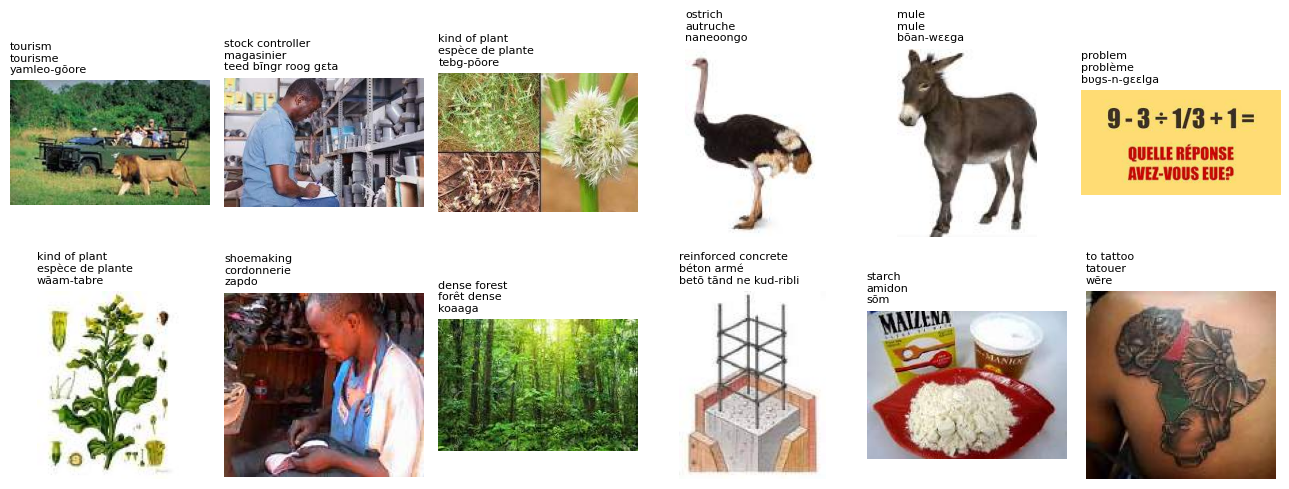

In [25]:
record_of = dict(zip(table["id"], table["_record"]))
_, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, (_, row) in zip(axes.ravel(), dataset.sample(12, random_state=seed).iterrows()):
    ax.imshow(Image.open(io.BytesIO(photo_file(records[record_of[row["id"]]]))))
    ax.set_title(
        f"{first_name(row['english'])[:22]}\n{first_name(row['french'])[:22]}\n{row['moore']}",
        fontsize=8,
        loc="left",
    )
    ax.axis("off")
plt.tight_layout()

## 5. Save and publish
The table with its photos is pushed to the public dataset `anyantudre/moore-image-lexicon` on Hugging Face, as three splits (train, validation, test). Notebook 2 loads it from there.

In [26]:
def image_entry(record, identifier):
    image = pdfs[record["photo"]["source"]].extract_image(photo_of(record)["xref"])
    return {"bytes": image["image"], "path": f"{identifier}.{image['ext']}"}


dataset.insert(1, "image", [image_entry(records[record_of[i]], i) for i in dataset["id"]])
splits = {}
for name in ("train", "validation", "test"):
    split = Dataset.from_pandas(
        dataset[dataset["split"] == name].reset_index(drop=True), preserve_index=False
    ).cast_column("image", ImageFeature())
    for language in ("english", "french", "moore"):
        split = split.cast_column(
            f"wrong_{language}", Sequence(Value("string"))
        )  # a split without any wrong option would otherwise get the type null
    splits[name] = split
DatasetDict(splits).push_to_hub("anyantudre/moore-image-lexicon", token=hf_token)

CommitInfo(commit_url='https://huggingface.co/datasets/anyantudre/moore-image-lexicon/commit/ca7bd78e3d2b75e63f996a8f8ce745d05d4ce209', commit_message='Upload dataset', commit_description='', oid='ca7bd78e3d2b75e63f996a8f8ce745d05d4ce209', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/anyantudre/moore-image-lexicon', endpoint='https://huggingface.co', repo_type='dataset', repo_id='anyantudre/moore-image-lexicon'), pr_revision=None, pr_num=None)